In [18]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# lijepiji stil
sns.set(style="whitegrid")

# root projekta = jedan nivo iznad notebooks/
PROJECT_ROOT = Path(os.getcwd()).parent.parent
METRICS_PATH = PROJECT_ROOT / "artifacts" / "metrics_summary.csv"
METRICS_PATH

WindowsPath('C:/Users/Korisnik/Desktop/web-automation/artifacts/metrics_summary.csv')

In [19]:
if not METRICS_PATH.exists():
    raise FileNotFoundError(f"Metrics CSV ne postoji: {METRICS_PATH}")

df = pd.read_csv(METRICS_PATH)
df.head()

,experiment_id,experiment_name,model_type,featureset,precision,recall,f1,roc_auc,top1_acc,support_pos,support_neg
0,1,EXP1_fuzzy_only,LogisticRegression,"[""f_ratio"", ""f_partial"", ""f_token_sort"", ""f_to...",0.8682,0.9655,0.9143,0.9890,0.8682,116,387
1,1,EXP1_fuzzy_only,RandomForest,"[""f_ratio"", ""f_partial"", ""f_token_sort"", ""f_to...",0.9182,0.8707,0.8938,0.9792,0.9182,116,387
2,1,EXP1_fuzzy_only,XGBoost,"[""f_ratio"", ""f_partial"", ""f_token_sort"", ""f_to...",0.9035,0.8879,0.8957,0.9782,0.9035,116,387
3,2,EXP2_fuzzy_plus_engineering,LogisticRegression,"[""f_ratio"", ""f_partial"", ""f_token_sort"", ""f_to...",0.8968,0.9741,0.9339,0.9943,0.8968,116,387
4,2,EXP2_fuzzy_plus_engineering,RandomForest,"[""f_ratio"", ""f_partial"", ""f_token_sort"", ""f_to...",0.9407,0.9569,0.9487,0.9963,0.9407,116,387


In [20]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   experiment_id    18 non-null     int64  
 1   experiment_name  18 non-null     object 
 2   model_type       18 non-null     object 
 3   featureset       18 non-null     object 
 4   precision        18 non-null     float64
 5   recall           18 non-null     float64
 6   f1               18 non-null     float64
 7   roc_auc          18 non-null     float64
 8   top1_acc         18 non-null     float64
 9   support_pos      18 non-null     int64  
 10  support_neg      18 non-null     int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 1.7+ KB


,experiment_id,precision,recall,f1,roc_auc,top1_acc,support_pos,support_neg
count,18.000000,18.000000,18.000000,18.000000,18.000000,18.000000,18.0,18.0
mean,2.000000,0.917056,0.945389,0.930533,0.990978,0.917056,116.0,387.0
std,0.840168,0.024465,0.037162,0.022589,0.007105,0.024465,0.0,0.0
min,1.000000,0.868200,0.870700,0.893800,0.978200,0.868200,116.0,387.0
25%,1.000000,0.903500,0.956900,0.914300,0.989000,0.903500,116.0,387.0
50%,2.000000,0.918200,0.956900,0.941700,0.994300,0.918200,116.0,387.0
75%,3.000000,0.933300,0.965500,0.948700,0.996000,0.933300,116.0,387.0
max,3.000000,0.948700,0.974100,0.952800,0.996500,0.948700,116.0,387.0


In [21]:
grouped = (
    df.groupby(["experiment_name", "model_type"])
      .agg(
          precision=("precision", "mean"),
          recall=("recall", "mean"),
          f1=("f1", "mean"),
          roc_auc=("roc_auc", "mean"),
          top1_acc=("top1_acc", "mean"),
          support_pos=("support_pos", "mean"),
          support_neg=("support_neg", "mean"),
      )
      .reset_index()
)

In [22]:
# F1 pivot: modeli vs eksperimenti
pivot_f1 = grouped.pivot(
    index="model_type",
    columns="experiment_name",
    values="f1",
)
pivot_f1

experiment_name,EXP1_fuzzy_only,EXP2_fuzzy_plus_engineering,EXP3_fuzzy_plus_engineering_plus_embeddings
model_type,,,
LogisticRegression,0.9143,0.9339,0.9417
RandomForest,0.8938,0.9487,0.9528
XGBoost,0.8957,0.9492,0.9447


In [23]:
# Top1 accuracy pivot
pivot_top1 = grouped.pivot(
    index="model_type",
    columns="experiment_name",
    values="top1_acc",
)
pivot_top1

experiment_name,EXP1_fuzzy_only,EXP2_fuzzy_plus_engineering,EXP3_fuzzy_plus_engineering_plus_embeddings
model_type,,,
LogisticRegression,0.8682,0.8968,0.9113
RandomForest,0.9182,0.9407,0.9487
XGBoost,0.9035,0.9333,0.9328


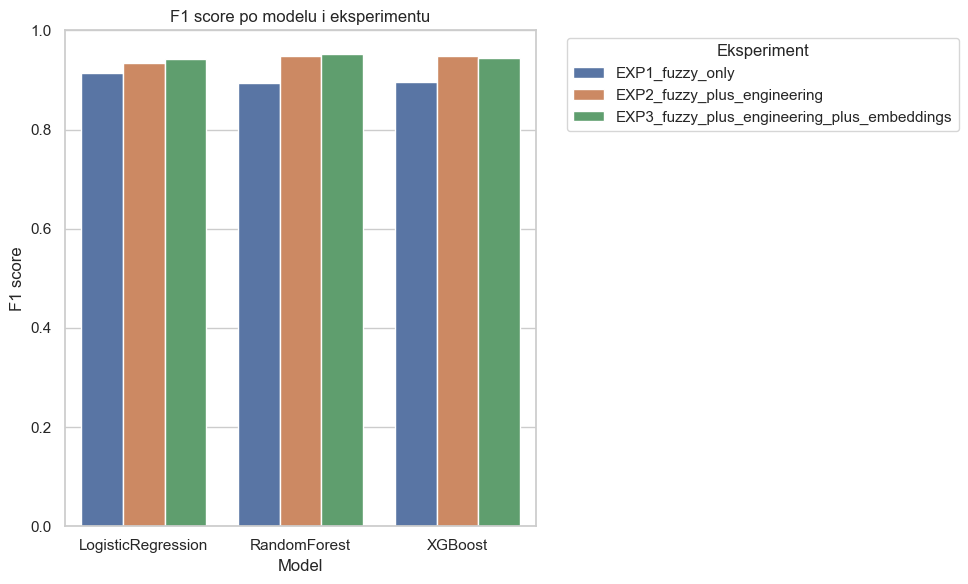

In [24]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=grouped,
    x="model_type",
    y="f1",
    hue="experiment_name",
)
plt.title("F1 score po modelu i eksperimentu")
plt.ylabel("F1 score")
plt.xlabel("Model")
plt.legend(title="Eksperiment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.ylim(0, 1.0)
plt.tight_layout()
plt.show()

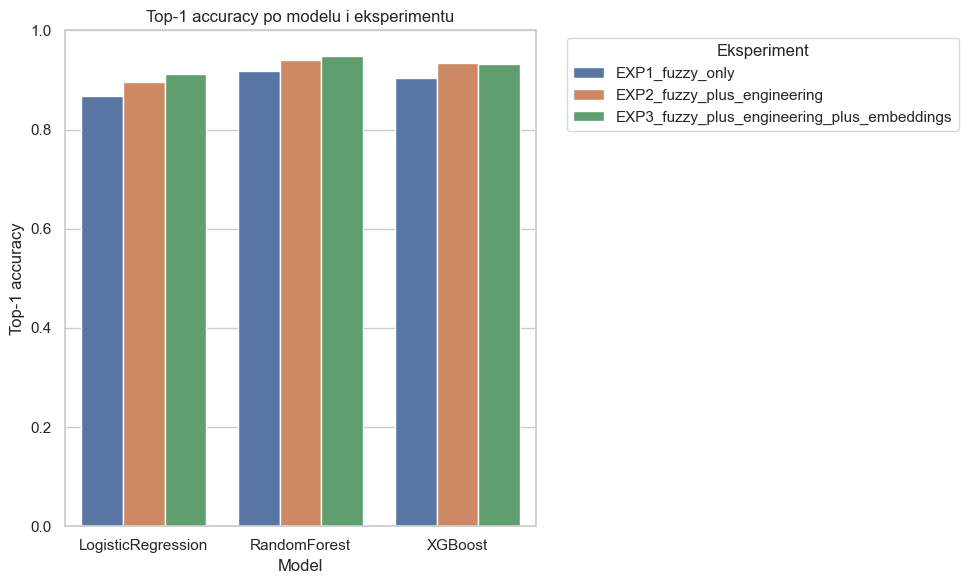

In [25]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=grouped,
    x="model_type",
    y="top1_acc",
    hue="experiment_name",
)
plt.title("Top-1 accuracy po modelu i eksperimentu")
plt.ylabel("Top-1 accuracy")
plt.xlabel("Model")
plt.legend(title="Eksperiment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.ylim(0, 1.0)
plt.tight_layout()
plt.show()

In [26]:
# definiraj metricu po kojoj biraš "najbolju" kombinaciju
metric = "top1_acc"  # ili "f1"

best = grouped.sort_values(metric, ascending=False).head(5)
best

,experiment_name,model_type,precision,recall,f1,roc_auc,top1_acc,support_pos,support_neg
7,EXP3_fuzzy_plus_engineering_plus_embeddings,RandomForest,0.9487,0.9569,0.9528,0.9965,0.9487,116.0,387.0
4,EXP2_fuzzy_plus_engineering,RandomForest,0.9407,0.9569,0.9487,0.9963,0.9407,116.0,387.0
5,EXP2_fuzzy_plus_engineering,XGBoost,0.9333,0.9655,0.9492,0.9960,0.9333,116.0,387.0
8,EXP3_fuzzy_plus_engineering_plus_embeddings,XGBoost,0.9328,0.9569,0.9447,0.9954,0.9328,116.0,387.0
1,EXP1_fuzzy_only,RandomForest,0.9182,0.8707,0.8938,0.9792,0.9182,116.0,387.0


In [27]:
best_per_experiment = (
    grouped.sort_values(metric, ascending=False)
           .groupby("experiment_name")
           .head(1)
           .reset_index(drop=True)
)
best_per_experiment

,experiment_name,model_type,precision,recall,f1,roc_auc,top1_acc,support_pos,support_neg
0,EXP3_fuzzy_plus_engineering_plus_embeddings,RandomForest,0.9487,0.9569,0.9528,0.9965,0.9487,116.0,387.0
1,EXP2_fuzzy_plus_engineering,RandomForest,0.9407,0.9569,0.9487,0.9963,0.9407,116.0,387.0
2,EXP1_fuzzy_only,RandomForest,0.9182,0.8707,0.8938,0.9792,0.9182,116.0,387.0
